In [1]:
import TEBD_code as tebd #[8]
import numpy as np
import matplotlib.pyplot as plt
from tenpy.networks.mps import MPS
from tenpy.algorithms.tebd import TEBDEngine
from tenpy.models.tf_ising import TFIChain

C:\Users\86183\tenpy\tools\optimization.py:307: UserWarning: Couldn't load compiled cython code. Code will run a bit slower.
  warnings.warn("Couldn't load compiled cython code. Code will run a bit slower.")


# Time Evolve Block Decimation

    "Calculations were performed using the TeNPy Library (version 0.10.0)\cite{tenpy}."

## 0. Abstract

In this report, I explore the time-evolving block decimation (TEBD) algorithm, a powerful tool in the field of tensor network methods. After introducing the theoretical foundations of the algorithm and tensor network theory, I discussed the implementation of TEBD in the context of the 1D spin chain in Ising model. Specifically, I examined the time evolution of spin components in both the $x$ and $z$ directions using TEBD. Additionally, I investigateD the efficiency of the algorithm and how it depends on factors such as the bond dimension and the size of the system. Through my analysis, I demonstrated the usefulness of TEBD in studying quantum systems and provide insight into its performance characteristics.

## 1. Theoretical background

Time-Evolving Block Decimation (TEBD) is a numerical method used to simulate the time evolution of quantum many-body systems, particularly those described by matrix product states (MPS)[1]. It is especially useful for one dimensional gapped Hamiltonian. 

TEBD takes the advantage that the low-energy states of a gapped, local Hamiltonian are those satisfying the area-law for the entanglement entropy[2], which only occupies a very small region in the Hilbert space. Hence, despite the Hilbert space for a quantum many-body system Hamiltonian is exponentially large in the number of system, the manifold of dominant, low energy states is not. Infact, these are the tensor network (TN) states. The key idea of TEBD is that in one spatial dimension, low energy quantum dynamics are often only
slightly entangled.

The most well-known TN states for 1D quantum many-body system is the Matrix Product State (MPS). Figure 1 is the TN for an infinite-MPS with 1-site unit cell. $\chi$ is the bond dimension of tensor $A$, which reflects the entanglement between subsystems. $d$ is the dimension of the Hilbert space of local Hamiltonian at each site.

![jupyter](./MPS_1.jpg)

<center>Figure 1: infinite-MPS with one tensor unit cell.</center>

All MPS can be written in the canonical form[3, 4] as follow: 

\begin{equation}
|\Psi \rangle = \sum_{i_1, \cdots, i_N} C_{i_1, \cdots, i_N} |i_1\rangle \otimes \cdots \otimes |i_N \rangle
\end{equation}

\begin{equation}
    C_{i_1 \cdots i_N} = \sum_{\alpha_1, \cdots, \alpha_{N - 1}} 
    \Gamma_{\alpha_1}^{[1]i_1} \lambda_{\alpha_1}^{[1]}
    \Gamma_{\alpha_1 \alpha_2}^{[2]i_2} \lambda_{\alpha_2}^{[2]}
    \Gamma_{\alpha_2 \alpha_3}^{[3]i_3} \lambda_{\alpha_3}^{[3]}
    \cdots 
    \Gamma_{\alpha_{N-1}}^{[N]i_N}
\end{equation}

This form is obtained by consecutive Schmidt decomposition[6], which is also known as the singular value decomposition(SVD). The $\lambda^{[i]}$s are the Schmidt coefficients, and are assumed to be the diagonal entries of a diagonal matrix to accomadate the tensor operation. i.e.

\begin{equation}
|\Psi \rangle = \sum_{\alpha_l}\lambda_{\alpha_{l}} |\Phi^{[1, \cdots, l - 1]}_{\alpha_l} \rangle \otimes |\Phi^{[l, \cdots, N]}_{\alpha_l}\rangle
\end{equation}

It is straight forward to show that $|\Phi_\alpha^{L(R)} \rangle$ are normalized eigen vectors of the reduced density matrix $\rho^{L(R)} = \text{tr}_{R(L)}\left( |\Psi\rangle \langle \Psi | \right)$, and $\lambda$s are the corresponding eigen values. Therefore, by considering the dimension of the reduced density matrices, $\lambda_{\alpha_l}$ should have dimension $d^{l}$. Hence in general, the bond dimension increases exponentially with the number of sites. However, numerical simulation shows that many of the components are non-important, only certain number of $\lambda_{\alpha_l}$ have significance influence. Thus, a process known as 'SVD compression' is implemented to compress the bond dimension, this is roughly presented in Figure 2:

![jupyter](./SVD_com.png)

<center>Figure 2: SVD compression approximation</center>

And the $\Gamma^{[m]i_j}$s are the change of basis between the Schmidt basis $|\Phi_\alpha^{L} \rangle \otimes |\Phi_\alpha^{R} \rangle$ and the local Hamiltonian basis $|i_j\rangle$.

Figure 3 shows the TN in this reperesentation:

![jupyter](./Canonical_2.png)

<center>Figure 3: finite-MPS with 4-site in canonical form.</center>

For a finite MPS, $\Gamma_1$ and $\Gamma_4$ should be two rank-2 tensors instead of rank-3. Here I make them rank-3 for consistancy with the other $\Gamma$s. In this case, $\Gamma_1(\Gamma_4)$ has shape $(1, p, \min(p, \chi))$.

### 1.1 Inner product

An inportant aspect in Tensor network is tensor contraction, different contraction order may result in different time complexity. Here is how to perform inner product of two wave functions. 

If I have two state vector and want to find thire inner product, it is the same as contraction of the two tensors that represent these two states. i.e. $\langle \Psi | \Phi \rangle = D_{i_1\cdots i_N} \left( C_{i_1\cdots i_N}\right)^*$. The TN representation is shown in Figure 4.

![jupyter](./Contraction_2.png)

<center>Figure 4: contraction of 2 finite-MPS in canonical form.</center>

The steps for this contraction is as follow, as shown in Figure 5:

![jupyter](./TN_contraction.jpg)

<center>Figure 5: iterative process of the contraction of 2 finite-MPS in canonical form.</center>

1. Pop the first tensor stored in the Gammas of $|\Phi \rangle$ and $\langle \Psi |$ and pop the first tensor stored in the lambdas of $|\Phi \rangle$ and $\langle \Psi |$.

2. Pop the first tensor stored in the lambdas of $|\Phi \rangle$, and pop the first tensor stored in the gammas of $|\Phi \rangle$.

3. Contract these 5 tensors to give a new rank-3 tensor with dimension $\chi \times p \times \chi$.

4. Insert this new tensor to position $0$ of the gammas of $|\Phi \rangle$.

5. Insert vector $(1, \cdots, 1)$ to position $0$ of the lambdas of $|\Phi \rangle$

6. Return the two new canonical decompositions.

The time complexity of this contraction is roughly $O\left( N\cdot d \chi^3\right)$, as shown in Figure 6:

![jupyter](./Contrac_complexity.png)

<center>Figure 6: time complexity for the contraction of two tensors</center>

## 2. Evolution 

The aim of this part is to update the decomposition of the time-evolved state $|\psi_t\rangle$ for increasing value pf a discretized time $t \in \{ \delta , 2\delta, \cdots, T \}$. The main idea is to divede the Hamiltonian $H$ into the Hamiltonian of two parts $H = F + G$, given that $H$ only contain single-body terms and neighboring interactions, i.e.

\begin{equation}
H = \sum_{l=1}^{N} K_1^{[l]} + \sum_{l=1}^{N-1} K_2^{[l, l+1]} = F + G
\end{equation}

\begin{equation}
F = \sum_{\text{even } l}\left( K_1^{[l]} + K_2^{[l, l+1]} \right) = \sum_{\text{even } l} F^{[l]}
\end{equation}

\begin{equation}
G = \sum_{\text{odd } l}\left( K_1^{[l]} + K_2^{[l, l+1]} \right) = \sum_{\text{odd } l} G^{[l]}
\end{equation}

For the transverse field Ising model on a 1D chain of $N$ spin-$\frac{1}{2}$ particles, the Hamiltonian is:

\begin{equation}
H = - J \sum_{i=1}^{N-1} \sigma_i^z \sigma_{i+1}^z - h \sum_{i=1}^N \sigma_i^x
\end{equation}

Here $\sigma_i^\alpha$ are the Pauli matrix act on spin $i$:

\begin{equation}
\sigma^x = \left(
\begin{array}
&0 &1 \\
1 &0
\end{array}\right) \quad, \quad
\sigma^y = \left(
\begin{array}
&0 &-i \\
i &0
\end{array}\right) \quad, \quad
\sigma^z = \left(
\begin{array}
&1 &0 \\
0 &-1
\end{array}\right)
\end{equation}

\begin{equation}
\therefore K_1^{[l]} = -h \, \sigma_l^x \quad, \quad K_2^{[l, l+1]} = -J \, \sigma_l^z \sigma_{l+1}^z
\end{equation}

The purpose of this step is to make the terms in each of the sum commute with each other. Then use Trotter expansion[8] to approximate $\exp \left(-i(F+G)T\right)$ to order $p$[5]:

\begin{equation}
e^{-i(F+G)T} = \left[ e^{-i(F+G)\delta} \right]^{T/\delta} \approx \left[ f_p\left(U_{F\delta}, U_{G\delta} \right) \right]^{T/\delta}
\end{equation}

Where $U_{F\delta}$ and $U_{G\delta}$ are expressed as a product of two-body gates $V_2^{[l]}$ and $W_2^{[l]}$, since $\left[F^{[l]}, F^{[l']}  \right] = \left[G^{[l]}, G^{[l']}  \right] = 0$:

\begin{equation}
U_{F\delta} = \prod_{\text{even }l}V_2^{[l]}, \quad V_2^{[l]} = e^{-i F^{[l]}\delta}
\end{equation}

\begin{equation}
U_{G\delta} = \prod_{\text{odd }l}W_2^{[l]}, \quad W_2^{[l]} = e^{-i G^{[l]}\delta}
\end{equation}

Then, by iteratively applying these two gates, the approximately evolved state can be found by:

\begin{equation}
|\tilde{\Psi}_{t+\delta} \rangle = f_p\left( U_{F\delta}, U_{G\delta} \right) |\tilde{\Psi}_{t} \rangle
\end{equation}

And use the following steps to update the decomposition[10], detailed derivation in appendix $A$:

### 2.1 Update the decomposition [6]

Supppose a unitary operatpr $V$ acts on qubits $l$ and $l+1$ of the system.

1. First define the following unnormalized eigen state of the corresponding reduced density matrices:

\begin{equation}
|\alpha\rangle = \lambda_{\alpha}^{[l - 1]} |\Phi_{\alpha}^{[1, \cdots, l-1]} \rangle \quad ,\quad \langle \alpha | \alpha \rangle = |\lambda_\alpha^{[l-1]}|^2
\end{equation}

\begin{equation}
|\gamma\rangle = \lambda_{\gamma}^{[l + 1]} |\Phi_{\gamma}^{[l + 1, \cdots, N]} \rangle \quad ,\quad \langle \gamma | \gamma \rangle = |\lambda_\gamma^{[l+1]}|^2
\end{equation}

2. Then define the vector $|ij\rangle$ and $|km \rangle$ as the state for quibits $|l, l+1 \rangle$, and hence define the following rank 4 tensor: 

\begin{equation}
\Theta_{\alpha \gamma}^{ij} = \sum_\beta \sum_{km} V^{ij}_{km} \Gamma^{[l]k}_{\alpha \beta} \lambda_\beta^{[l]} \Gamma^{[l+1]m}_{\beta \gamma}
\end{equation}

\begin{equation}
V_{km}^{ij} = \langle ij | V | km \rangle
\end{equation}

3. Next find the reduced density matrix $\rho'^{[l,\cdots, N]}$, and remember $|\gamma\rangle$ are unnormalized state:

\begin{equation}
\rho'^{[l,\cdots, N]} = \sum_{j, j', \gamma, \gamma'} \left( \sum_{\alpha, i}
\langle \alpha | \alpha \rangle \cdot \Theta_{\alpha \gamma}^{ij} \, \left(\Theta_{\alpha \gamma'}^{ij'}  \right)^* \right)
|j\gamma \rangle \langle j' \gamma'|
\end{equation}

4. Then find the eigen vector of matrix $\rho'^{[l,\cdots, N]}$, which should take the form:

\begin{equation}
|\Phi_\beta'^{[l,\cdots, N]} \rangle = \sum_{j, \gamma} \Gamma_{\beta \gamma}'^{[l+1]j} |j\gamma\rangle
\end{equation}

Hence, the new tensor $\Gamma'^{[l+1]}$ is given by the components of the vector $|\Phi_\beta'^{[l,\cdots, N]} \rangle$, and $\lambda'^{[l]}$ is given by the corresponding eigen values.

5. Finally, update $\lambda'^{[l]}\Gamma'^{[l]}$ according to:

\begin{equation}
\lambda_\beta'^{[l]}\Gamma_{\alpha \beta}'^{[l]i} = \sum_{j, \gamma} \left(
\Gamma_{\beta \gamma}'^{[l+1]j}\right)^* \cdot \Theta_{\alpha \gamma}^{ij} \, 
\langle \gamma | \gamma \rangle
\end{equation}

Notice that in step 4, the bond dimension is increased, this means this process increases the entanglement entropy. However, this increament is ignored by SVD compression during simulation. 

## 3. Initialization

The aim of this section is to construct the initial decomposition for state $|\Psi_0 \rangle$. In [7], three methods are introduced, based on the assumption that $|\Psi_0 \rangle$ is related to the ground state $\Psi_{gr}$ of the Hamiltonian by a sufficiently local operator, i.e. $|\Psi_0 \rangle = Q |\Psi_{gr}\rangle$:

1. By extracting it from the solution of the Density Matrix Renormalization Group (DMRG) method.

2. By considering any product state, and by using the present scheme to simulate an evolution in imaginary time $\tau$ according to the Hamiltoniam $H$:

\begin{equation}
|\Phi_\otimes\rangle = |\phi^{[1]}\rangle \otimes \cdots \otimes |\phi^{[N]}\rangle \quad, \quad \langle \Phi_\otimes | \Phi_{gr} \rangle \ne 0
\end{equation}

\begin{equation}
|\Phi_{gr}\rangle = \lim_{\tau \to \infty} \frac{\exp \left( -H\tau \right)|\Phi_\otimes \rangle}{|| \exp \left( -H\tau \right)|\Phi_\otimes \rangle ||}
\end{equation}

3. By simulating an adiabatic evolution from some product state $|\Phi'_\otimes \rangle$ to $|\Psi_0\rangle$ through a time-dependent Hamiltonian that smoothly interpolates between a local Hamiltonian $H'$ s.t. it has $|\Phi'_\otimes \rangle$ as its ground state and Hamiltonian $H$.

### 3.1 Randomly generate an initial MPS

The method 2 in previous section provides a alternative way to find the ground state energy of a Hamiltonian. However, before it can be implemented, I need an initial MPS state that is actually a low energy state represented in its canonical decomposition.

The general idea is randomly generate orthonormal eigenvectors and eigen values of the reduced dencity matrices of subsystems.

The following trivial results come from the comparison betwwen the canonical form and Schmidt decomposition:

\begin{equation}
|\phi_{\alpha_l}^{[1, \cdots, l]}\rangle = \sum_{i_1, \cdots, i_l} \sum_{\alpha_1, \cdots, \alpha_{(l-1)}}
\Gamma_{\alpha_1}^{[1]i_1} \lambda_{\alpha_1}^{[1]} \,
\Gamma_{\alpha_1 \alpha_2}^{[2]i_2} \lambda_{\alpha_2}^{[2]} \, \cdots \,
\Gamma_{\alpha_{l-1}\, \alpha_{l}}^{[l]i_l} \, 
|i_1\rangle \otimes \cdots \otimes |i_l\rangle
\end{equation}

\begin{equation}
\therefore |\phi_{\alpha_l}^{[1, \cdots, l]}\rangle = \sum_{i_l} \sum_{\alpha_{l-1}}
\lambda_{\alpha_{l-1}}^{[l-1]} \, \Gamma_{\alpha_{l-1} \, \alpha_l}^{[l]i_l} \, |\phi_{\alpha_{(l-1)}}^{[1, \cdots, l-1]}\rangle \otimes |i_l \rangle
\end{equation}

Then take the inner product with itself: 

\begin{equation}
\langle \phi_{\alpha_l'}^{[1, \cdots, l]} |\phi_{\alpha_l}^{[1, \cdots, l]}\rangle = 
\sum_{i_l} \sum_{\alpha_{l-1}}
|\lambda_{\alpha_{l-1}}^{[l-1]}|^2 \, \Gamma_{\alpha_{l-1} \, \alpha_l}^{[l]i_l} \, 
\, \left( \Gamma_{\alpha_{l-1} \, \alpha_l'}^{[l]i_l}\right)^* \, =
\delta_{\alpha_l', \alpha_l}
\end{equation}

\begin{equation}
\langle \phi_{\alpha_l'}^{[1, \cdots, l]} |\phi_{\alpha_l}^{[1, \cdots, l]}\rangle = 
\sum_{i_l} \sum_{\alpha_{l-1}}
\left( \lambda_{\alpha_{l-1}}^{[l-1]} \, \Gamma_{\alpha_{l-1} \, \alpha_l}^{[l]i_l} \right) \, 
\, \left(\lambda_{\alpha_{l-1}}^{[l-1]} \, \Gamma_{\alpha_{l-1} \, \alpha_l'}^{[l]i_l}\right)^* \, =
\delta_{\alpha_l', \alpha_l}
\end{equation}

\begin{equation}
\therefore
\sum_{\alpha_{l-1}}
|\lambda_{\alpha_{l-1}}^{[l-1]}|^2 \, \sum_{i_l} 
\, \Gamma_{\alpha_{l-1} \, \alpha_l}^{[l]i_l} \, 
\, \left( \Gamma_{\alpha_{l-1} \, \alpha_l'}^{[l]i_l}\right)^* \, =
\delta_{\alpha_l', \alpha_l}
\end{equation}

And similarly:

\begin{equation}
\sum_{\alpha_{l}}
|\lambda_{\alpha_{l}}^{[l]}|^2 \, \sum_{i_{l}} 
\, \Gamma_{\alpha_{l - 1} \, \alpha_{l}}^{[l]i_{l}} \, 
\, \left( \Gamma_{\alpha_{l - 1}' \, \alpha_{l}}^{[l]i_{l}}\right)^* \, =
\delta_{\alpha_{l - 1}'\, , \alpha_{l - 1}}
\end{equation}

Hence, these two equations are the only two constrains required for the canonical decomposition. Notice that $\rho'^{[l,\cdots, N]}$ in section 2.1 is a Hermitian matrix, and hence the update always satisfies these two rules. They can be represented elegently in the tensor network representation as shown in Figure 7:

![jupyter](./Conditions.png)

<center>Figure 7: two conditions for canonical decomposition in tensor netwrok notation, notice these two conditions also implies the normalization condition of $\lambda^2$s, which is the trace of corresponding reduced density matrices.</center>

The first condition can be satisfied as long as the contraction between the rank 3 tensor resulted from the second summation and the vector $|\lambda_{\alpha_{l-1}}^{[l-1]}|^2$ gives an identity matrix. Theoratically, there are $p^l$ different number of $a_l$, which means $\delta_{\alpha_l', \alpha_l}$ is an identity matrix with dimension $p^l \times p^l$. Thus, $\Gamma$s can be found by randomly generate a orthornolmal matrix with dimention $p^l \times p^l$, then divide it into $p^{l-1}$ parts and use the previous $\lambda$ to normalize each part. If $p^l > \chi$, remove the last $p^l - \chi$ rows.

The above process can be implemented accoeding to the following recipe:

1. Randomly generate all the lambdas.

2. Randomly generate an othonormal matrix with dimension $p^l \times p^l$.

3. Remove the last $\max(0, p^l - \chi)$ rows.

4. Devide the matrix into $p^{l-1}$ parts, and normalize according to $\lambda^{[l-1]}$.

5. Repeat for all $l$.

## 4. Implementation of TEBD

### 4.1 Imaginary time evolution

#### 4.1.1 Find the ground state energy

In [2]:
J , h= 1, 1
L, chi, trotter_order, N_steps = 10, 20, 2, 10
E, p, M, trunc_err = tebd.gs_energy_ising_finite(L, h, chi, N_steps, trotter_order)
E_exact = tebd.finite_gs_energy(L, J, h)

In [3]:
energy = []
exact = []
Ls = []
for L in range(5, 18, 1):
    E, p, M, trunc_err = tebd.gs_energy_ising_finite(L, h, chi, N_steps, trotter_order)
    E_exact = tebd.finite_gs_energy(L, J, h)
    energy.append(E)
    exact.append(E_exact)
    Ls.append(L)

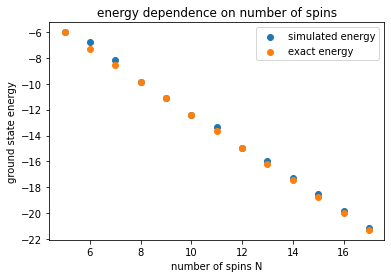

In [4]:
plt.scatter(Ls, energy, label = 'simulated energy')
plt.scatter(Ls, exact, label = 'exact energy')
plt.xlabel('number of spins N')
plt.ylabel('ground state energy')
plt.title('energy dependence on number of spins')
plt.legend()

#### 4.1.2 Energy evolution on imaginary time with $N = 15, \chi = 16$

In [5]:
J , h= 1, 1
L, chi, trotter_order, N_steps = 15, 16, 2, 0
E, p, M, trunc_err = tebd.gs_energy_ising_finite(L, h, chi, N_steps, trotter_order)

In [6]:
# evolve_mps_imag_time(L, g, chi, N_steps, psi, dt, trotter_order = 2) return E, psi, M, trunc_err
dt = 0.01
N_steps = 10
energy_2 = []
time_2 = []
exact_2 = []
current_psi = p
for i in range(0, 20, 1):
    E, current_psi, M, trunc_err = tebd.evolve_mps_imag_time(L, h, chi, N_steps, current_psi, dt, trotter_order)
    energy_2.append(E)
    time_2.append(i)
    exact_2.append(E_exact)

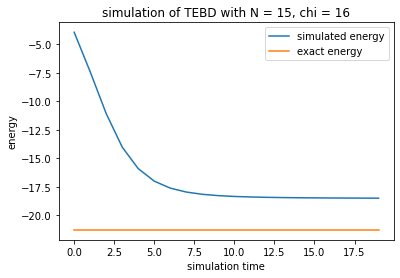

In [7]:
plt.title('simulation of TEBD with N = 15, chi = 16')
plt.plot(time_2, energy_2, label = 'simulated energy')
plt.plot(time_2, exact_2, label = 'exact energy')
plt.xlabel('simulation time')
plt.ylabel('energy')
plt.legend()

Text(0, 0.5, 'energy')

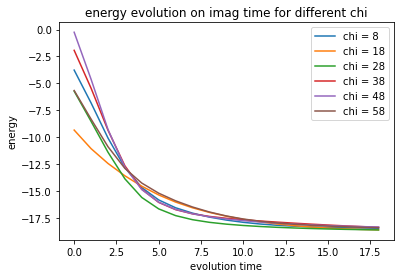

In [8]:
dt = 0.01
N_steps = 10
energies = []

for chi in range(8, 60, 10):
    E, p, M, trunc_err = tebd.gs_energy_ising_finite(L, h, chi, 0, trotter_order)
    energy_2 = []
    time_2 = []
    current_psi = p
    for i in range(0, 19, 1):
        E, current_psi, M, trunc_err = tebd.evolve_mps_imag_time(L, h, chi, N_steps, current_psi, dt, trotter_order)
        energy_2.append(E)
        time_2.append(i)
    
    energies.append(energy_2)
    plt.plot(time_2, energy_2, label = str('chi = ' + str(chi)))


plt.legend()
plt.title('energy evolution on imag time for different chi')  
plt.xlabel('evolution time')
plt.ylabel('energy')
    

#### 4.1.3 Spin evolution on imaginary time with $N = 15, \chi = 16$

In [9]:
J , h= 1, 1
L, chi, trotter_order, N_steps = 15, 16, 2, 0
E, p, M, trunc_err = tebd.gs_energy_ising_finite(L, h, chi, N_steps, trotter_order)

In [10]:
sigmax = []
sigmaz = []
time_3 = []

dt = 0.01
N_steps = 10
current_psi = p
for i in range(0, 20, 1):
    E, current_psi, M, trunc_err = tebd.evolve_mps_imag_time(L, h, chi, N_steps, current_psi, dt, trotter_order)
    sigmax.append(tebd.sigma_x(current_psi))
    sigmaz.append(tebd.sigma_z(current_psi))
    time_3.append(i)


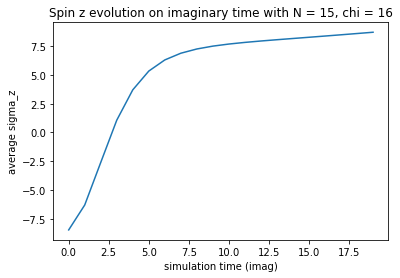

In [11]:
plt.plot(time_3, sigmaz)
plt.title('Spin z evolution on imaginary time with N = 15, chi = 16')
plt.xlabel('simulation time (imag)')
plt.ylabel('average sigma_z')
plt.show()

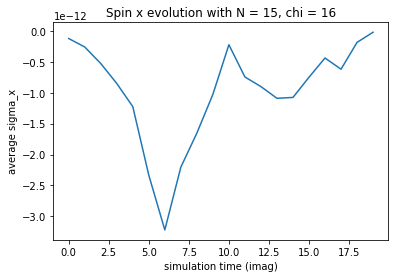

In [12]:
plt.plot(time_3, sigmax)
plt.title('Spin x evolution with N = 15, chi = 16')
plt.xlabel('simulation time (imag)')
plt.ylabel('average sigma_x')
plt.show()

#### 4.1.4 error dependence on $\chi$

In [13]:
J , h= 1, 1
L, chi, trotter_order, N_steps = 15, 2, 2, 20
E, p, M, trunc_err = tebd.gs_energy_ising_finite(L, h, chi, N_steps, trotter_order)
E_exact = tebd.finite_gs_energy(L, J, h)

In [14]:
N_steps = 20
dt = 0.01

chi_s = []
tr_error = []
val_error = []

for chi in range(2, 10, 1):
    E, current_psi, M, trunc_err = tebd.evolve_mps_imag_time(L, h, chi, N_steps, current_psi, dt, trotter_order)
    chi_s.append(chi)
    tr_error.append(trunc_err)
    val_error.append((E - E_exact)/ E_exact)

Text(0, 0.5, 'truncation error')

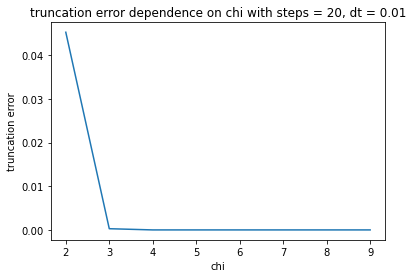

In [15]:
plt.plot(chi_s, tr_error)
plt.title('truncation error dependence on chi with steps = 20, dt = 0.01')
plt.xlabel('chi')
plt.ylabel('truncation error')

Text(0, 0.5, 'error between simulated energy and exact energy')

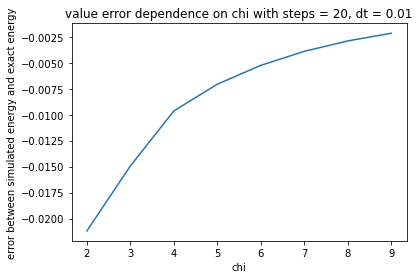

In [16]:
plt.plot(chi_s, val_error)
plt.title('value error dependence on chi with steps = 20, dt = 0.01')
plt.xlabel('chi')
plt.ylabel('error between simulated energy and exact energy')

#### 4.1.5 Time complexity dependence on $\chi$

In [ ]:
timingCompact = []
chi_time = [i for i in range(2, 13, 2)]
for i in chi_time:
    print(f"chi={i}")
    result = %timeit -o tebd.gs_energy_ising_finite(12, 1, i, 10, 2)
    timingCompact.append(result)

In [ ]:
t = [time.average for time in timingCompact]
time_error = [time.stdev for time in timingCompact]
plt.errorbar(chi_time, t, yerr = time_error)
plt.title('time complexity dependence on chi, with N = 15')
plt.yscale('log')
plt.legend()
plt.xlabel('chi')
plt.ylabel('time')
plt.show()

#### 4.1.6 Time compexity dependence on $N$

In [ ]:
timingCompact_N = []
N_time = [i for i in range(5, 21, 3)]
for i in N_time:
    print(f"N={i}")
    result = %timeit -o tebd.gs_energy_ising_finite(N, 1, 16, 10, 2)
    timingCompact_N.append(result)

In [ ]:
t_N = [time.average for time in timingCompact_N]
time_error_N = [time.stdev for time in timingCompact_N]
plt.errorbar(N_time, t_N, yerr = time_error_N)
plt.title('time complexity dependence on N, with chi = 16')
plt.yscale('log')
plt.legend()
plt.xlabel('N')
plt.ylabel('time')
plt.show()

### 4.2 Real time evolution

The real time evolution of the spin operator in the 1D Ising model is a complex problem, and there is no simple closed-form expression for it. However, it can be numerically calculated using methods like Time-evolving Block Decimation(TEBD). 

#### 4.2.1 Energy evolution on real time with $N = 10, \chi = 20$

In [18]:
J , h= 1, 1
L, chi, trotter_order, N_steps = 10, 20, 2, 10
E, p, M,trunc_err = tebd.gs_energy_ising_finite(L, h, chi, N_steps, trotter_order)
E_exact = tebd.finite_gs_energy(L, J, h)

In [19]:
dt = 0.001
N_steps_real = 4
new_psi = p
time_4 = []
sigmax_4 = []
sigmaz_4 = []
energy_4 = []
exact_energy_4 = []

for i in range(600):
    new_psi = tebd.evolve_mps_real_time(L, h, chi, N_steps_real, new_psi, dt, trotter_order)
    sigmax_4.append(tebd.sigma_x(new_psi))
    sigmaz_4.append(tebd.sigma_z(new_psi))
    time_4.append(i)
    energy_4.append(tebd.find_energy(L, new_psi))
    exact_energy_4.append(E_exact)

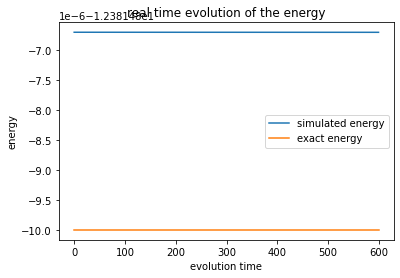

In [20]:
plt.plot(time_4, energy_4, label = 'simulated energy')
plt.plot(time_4, exact_energy_4, label = 'exact energy')
plt.title('real time evolution of the energy')
plt.xlabel('evolution time')
plt.ylabel('energy')
plt.legend()

#### 4.2.2 Spin evolution on real time with $N = 10, \chi = 20$ start from a ground state

No handles with labels found to put in legend.


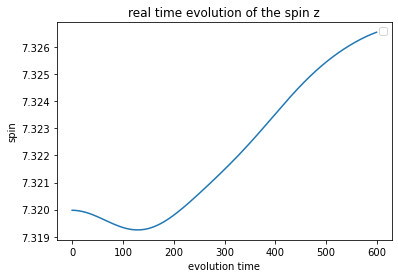

In [21]:
plt.plot(time_4, sigmaz_4)
plt.title('real time evolution of the spin z')
plt.xlabel('evolution time')
plt.ylabel('spin')
plt.legend()

No handles with labels found to put in legend.


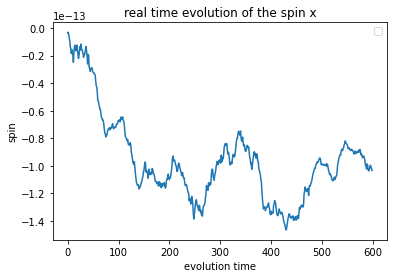

In [22]:
plt.plot(time_4, sigmax_4)
plt.title('real time evolution of the spin x')
plt.xlabel('evolution time')
plt.ylabel('spin')
plt.legend()

Spin $x$ is conserved as expected due to charge conservation.

#### 4.2.3 Spin evolution on real time with $N = 10, \chi = 20$ start from a random state

In [24]:
J , h= 1, 1
L, chi, trotter_order, N_steps = 10, 20, 2, 0
E, p, M, trunc_err = tebd.gs_energy_ising_finite(L, h, chi, N_steps, trotter_order)
E_exact = tebd.finite_gs_energy(L, J, h)

In [ ]:
dt = 0.0001
N_steps_real = 40
new_psi = p
time_5 = []
sigmax_5 = []
sigmaz_5 = []
energy_5 = []
exact_energy_5 = []

for i in range(600):
    new_psi = tebd.evolve_mps_real_time(L, h, chi, N_steps_real, new_psi, dt, trotter_order)
    sigmax_5.append(tebd.sigma_x(new_psi))
    sigmaz_5.append(tebd.sigma_z(new_psi))
    time_5.append(i)
    energy_5.append(tebd.find_energy(L, new_psi))
    exact_energy_5.append(E_exact)

In [ ]:
plt.plot(time_5, sigmaz_5, label = 'sigma z')
plt.plot(time_5, sigmax_5, label = 'sigma x')
plt.legend()
plt.title('real time evolution of spin_x and spin_z')
plt.xlabel('evolution time (real)')
plt.ylable('spin component')

    #Note: My computer runs very slow and I don't have enough time to run all the code presented here. -- Ray#

## 5. Improvements and conclusions

In quantum mechanics the representation of wavefunction is exponentially complex. In real world, the whole Hilbert space is far to large. Tensor neteork provide a way to work with the low energy and slightly entangled state only, which occupy a small manifold in Hilbert space. TEBD is based on singular value decomposition and SVD compression, it provide a method to find the ground state energy. However, there are many other method that are more efficient then TEBD, one of a well-known one is Density Matrix Renormalization Group(DMRG)[9].It is based on mixed-canonical decomposition and Variational compression, which gives more accuracy than SVD compression. Both DMRG and TEBD works well for 1D gapped Hamiltonian. For Gapless system, there is a method known as MERA[10] to give the neccessary corrections.

## References

    [1] Perez-Garcia, David, et al. "Matrix product state representations." arXiv preprint quant-ph/0608197 (2006).

    [2] T.Xiang, J. Luo, Z. Su, Phy. Rev. B 64, 104414 (2001); O. Legaza, J. Solyom, condmat/0305336; O.Legaza, J.Solyom, Phys. Rev, B 70, 205118 (2004); G. Vidal, J. I. Latorre, E. Rico, A. Kitaev, Physs. Rev. Lett. 71, 666 (1993); M. Plenio, J. Eisert, J. Dreifig, M. Cramer, Phys. Rev. Lett. 94, 060403 (2005)

    [3] E. Schmidt, Math. Ann. 63. 433 (1907); A.Ekert and P. L. Knight, Am. J. Phys. 63, 415 (1995); A. Oeres, Quantum Theory: Concepts and Methods (Kluwer Academic Publishers, Dordrecht, 1995)

    [4] G. Vidal, Phys. Rev. Lett. 98. 070201 (2007); R, Orus, G. Vidal, Phys. Rev. B 78, 155117 (2008)

    [5] M. Suzuki, Phys. Lett. A 146, 319 (1990); J. Math. Phys.(N.Y.) 32, 400 (1991). For third and fourth order expansions, see also A. T. Sornborger and E. D. Stewart, quantph/9809009.

    [6] G. Vidal, Phys. Rev. Lett. 91, 147902 (2003)

    [7] Vidal, G. (2004). Efficient simulation of one-dimensional quantum many-body systems. Physical review letters, 93(4), 040502.

    [8] Github repo: https://github.com/tenpy
    [9] S. R. White, Phys. Rev. B 48, 10345 (1993); S. Rommerand S. O¨stlund, Density Matrix Renormalization(Springer-Verlag, Berlin, 1999)
    [10] Nayak, S. P., Rai, S. C., & Pradhan, S. K. (2015, December). MERA: a multi-clustered energy efficient routing algorithm in WSN. In 2015 International Conference on Information Technology (ICIT) (pp. 37-42). IEEE.

## Appendix A: update of canonical decomposition

The Schmidt decomposition of a state vector is:

\begin{equation}
|\Psi\rangle = \sum_\alpha \lambda_\alpha |\Phi_\alpha^{[A]}\rangle \, \otimes \, |\Phi_\alpha^{[B]}\rangle
\end{equation}

And the canonical form for a finite MPS state is:

\begin{equation}
|\Psi\rangle = 
\sum_{\{\alpha \}} \sum_{\{i \}}\left(
\Gamma_{\alpha_1}^{[1]i_1} \, \lambda_{\alpha_1}^{[1]} \, \Gamma_{\alpha_1 \alpha_2}^{[2]i_2} \, \lambda_{\alpha_2}^{[2]} \cdots 
\lambda_{\alpha_{N-1}}^{[N-1]}\, \Gamma_{\alpha_{N-1}}^{[N]i_N} 
\right) \, |i_1\rangle \otimes \cdots \otimes | i_N\rangle
\end{equation}

Compare the above two expression gives:

\begin{equation}
|\Phi_{\alpha_l}^{[1, \cdots, l]}\rangle = \sum_{i_1, \cdots, i_l}\sum_{\alpha_1, \cdots, \alpha_l} \, \left(
\Gamma_{\alpha_1}^{[1]i_1} \, \lambda_{\alpha_1}^{[1]} \, \Gamma_{\alpha_1 \alpha_2}^{[2]i_2} \, \lambda_{\alpha_2}^{[2]} \cdots 
\Gamma_{\alpha_{l-1}\alpha_l}^{[l]i_l} 
\right)\, |i_1\rangle \otimes \cdots \otimes | i_l\rangle
\end{equation}

\begin{equation}
|\Phi_{\alpha_l}^{[l+1, \cdots, N]}\rangle = \sum_{i_{l+1}, \cdots, i_N}\sum_{\alpha_{l+1}, \cdots, \alpha_N} \, \left(
\Gamma_{\alpha_l \alpha_{l+1}}^{[l+1]i_{l+1}} \cdots \lambda_{\alpha_{N - 1}}^{[N-1]} \, \Gamma_{\alpha_{N-1}}^{[N]i_N}
\right)\, |i_{l+1}\rangle \otimes \cdots \otimes | i_N\rangle
\end{equation}

Lemma 2 from [6] says:

$\textbf{Lemma 2: }$ Updating the decomposition of state $|\Psi\rangle$ after a unitary operation $V$ acts on qubits $l$ and $l+1$ does only involve transforming $\Gamma^{[l]}, \lambda^{[l]}$ and $\Gamma^{[l+1]}$. 

regard $|Psi\rangle$ as belonging to $4$ subsystems:

\begin{equation}
\mathcal{H=J\otimes H_l \otimes H_{l+1} \otimes K}
\end{equation}

$\mathcal{J}$ is spanned by eigenvectors of the reduced density matrix:

\begin{equation}
\rho^{[1, \cdots, l-1]} = \sum_\alpha |\alpha \rangle \langle \alpha | \quad , \quad |\alpha\rangle = \lambda_\alpha^{[l-1]} |\Phi_\alpha^{[1, \cdots, l-1]}
\end{equation}

$\mathcal{K}$ is spanned by eigenvectors of the reduced density matrix:

\begin{equation}
\rho^{[l+2, \cdots, N]} = \sum_\gamma |\gamma \rangle \langle \gamma | \quad , \quad |\gamma\rangle = \lambda_\gamma^{[l+1]} |\Phi_\gamma^{[1+2, \cdots, N]}
\end{equation}

And $\mathcal{H_l, H_{l+1}}$ correspond, respectively, to quibits $l$ and $l+1$.

Therefore, a state $|\Psi \rangle$ can be written as:

\begin{equation}
|\Psi\rangle = \sum_{\alpha, \beta, \gamma} \sum_{i, j}
\, \Gamma_{\alpha \beta}^{[l]i} \,  \lambda_\beta^{[l]} \, \Gamma_{\beta \gamma}^{[l+1]j} \,
|\alpha \rangle \otimes |i\rangle \otimes |j\rangle \otimes |\gamma \rangle
\end{equation}

Here $|i\rangle$ represents the local state of quibit $l$, and $|j\rangle$ represents quibit $(l+1)$.

Now consider unitary operator $V$ acts on this state:

\begin{equation}
|\Psi'\rangle = V|\Psi\rangle = \sum_{\alpha, \gamma}\sum_{i, j} \Theta_{\alpha \gamma}^{ij}
\, |\alpha \rangle \otimes |i\rangle \otimes |j\rangle \otimes |\gamma \rangle
\end{equation}

Where the rank-4 tensor $\Theta$ is defined as follow:

\begin{equation}
\Theta_{\alpha \gamma}^{ij} = \sum_\beta \sum_{km} V^{ij}_{km} \Gamma^{[l]k}_{\alpha \beta} \lambda_\beta^{[l]} \Gamma^{[l+1]m}_{\beta \gamma}
\end{equation}

The reduced density matrix of subsystem $[l+1, \cdots, N]$ then takes the form:

\begin{equation}
\rho'^{(l+1)\mathcal{K}} = \text{tr}_{\mathcal{J}l} |\Psi'\rangle \langle \Psi'| = 
 \sum_{j, j', \gamma, \gamma'} \left( \sum_{\alpha, i}
\langle \alpha | \alpha \rangle \cdot \Theta_{\alpha \gamma}^{ij} \, \left(\Theta_{\alpha \gamma'}^{ij'}  \right)^* \right)
|j\gamma \rangle \langle j' \gamma'|
\end{equation}

And its eigen vectors $\{ |\Phi_\beta^{'[(l+1)\mathcal{K}]}\rangle \}$ satisfies:

\begin{equation}
|\Phi_{\beta}^{'[(l+1)\mathcal{K}]} \rangle = \sum_{j, \gamma} \Gamma_{\beta, \gamma}^{'[l+1]j} |j\gamma\rangle
\end{equation}

With eigen values $\lambda_\beta^{'[l]}$.

Next consider the SD, $|\Psi'\rangle = \sum \lambda_\beta^{'[l]} |\Phi_\beta^{'[\mathcal{J}l]}\rangle \otimes |\Phi_\beta^{'[(l+1)\mathcal{K}]}\rangle$. Hence I have:

\begin{equation}
\lambda_\beta^{'[l]} |\Phi_\beta^{'[\mathcal{J}l]}\rangle = \langle \Phi_\beta^{'[(l+1)\mathcal{K}]} | \Psi'\rangle 
= \left[
\sum_{j, \gamma} \left(
\Gamma_{\beta\gamma}^{'[l+1]i}
\right)^* \, \langle j\gamma|
\right]\cdot \left[
\sum_{\alpha, i, j', \gamma'} \Theta_{\alpha \gamma'}^{ij'} |\alpha i j \gamma\rangle
\right]
\end{equation}

\begin{equation}
\therefore \lambda_\beta^{'[l]} |\Phi_\beta^{'[\mathcal{J}l]}\rangle = 
\sum_{\alpha i  j \gamma}\, \langle \gamma|\gamma\rangle \left(
\Gamma_{\beta\gamma}^{'[l+1]i}
\right)^* \Theta_{\alpha \gamma}^{ij} \, |\alpha i \rangle
\end{equation}

And I also have $|\Phi_\beta^{'[\mathcal{J}l]}\rangle = \sum_{i, \alpha} \Gamma_{\alpha\beta}^{'[l]i}\,|\alpha i\rangle$. Yhus, compare this two expression gives:

\begin{equation}
\lambda_\beta'^{[l]}\Gamma_{\alpha \beta}'^{[l]} = \sum_{j, \gamma} \left(
\Gamma_{\beta \gamma}'^{[l+1]j}\right)^* \cdot \Theta_{\alpha \gamma}^{ij} \, 
\langle \gamma | \gamma \rangle
\end{equation}

## Appendix B: example code from www.tensor.net for infinite spin chain using TEBD*

This code first demonstrates the use of imaginary time evolution to find the ground state of an infinite (translation-invariant) quantum system in D=1 dimensions.

    

Computational cost: $\mathcal{O}(d χ^3)$

 

Based on a 2-site unit cell (A-B pattern)



Makes use of the canonical form for MPS 

In [ ]:
def doTEBD(hamAB: np.ndarray,
           hamBA: np.ndarray,
           A: np.ndarray,
           B: np.ndarray,
           sAB: np.ndarray,
           sBA: np.ndarray,
           chi: int,
           tau: float,
           evotype: Optional[str] = 'imag',
           numiter: Optional[int] = 1000,
           midsteps: Optional[int] = 10,
           E0: Optional[float] = 0.0):
    """
    Implementation of time evolution (real or imaginary) for MPS with 2-site unit
    cell (A-B), based on TEBD algorithm.
    Args:
    hamAB: nearest neighbor Hamiltonian coupling for A-B sites.
    hamBA: nearest neighbor Hamiltonian coupling for B-A sites.
    A: MPS tensor for A-sites of lattice.
    B: MPS tensor for B-sites of lattice.
    sAB: vector of weights for A-B links.
    sBA: vector of weights for B-A links.
    chi: maximum bond dimension of MPS.
    tau: time-step of evolution.
    evotype: set real (evotype='real') or imaginary (evotype='imag') evolution.
    numiter: number of time-step iterations to take.
    midsteps: number of time-steps between re-orthogonalization of the MPS.
    E0: specify the ground energy (if known).
    Returns:
    np.ndarray: MPS tensor for A-sites;
    np.ndarray: MPS tensor for B-sites;
    np.ndarray: vector sAB of weights for A-B links.
    np.ndarray: vector sBA of weights for B-A links.
    np.ndarray: two-site reduced density matrix rhoAB for A-B sites
    np.ndarray: two-site reduced density matrix rhoAB for B-A sites
    """

    # exponentiate Hamiltonian
    d = A.shape[1]
    if evotype == "real":
        gateAB = expm(1j * tau * hamAB.reshape(d**2, d**2)).reshape(d, d, d, d)
        gateBA = expm(1j * tau * hamBA.reshape(d**2, d**2)).reshape(d, d, d, d)
    elif evotype == "imag":
        gateAB = expm(-tau * hamAB.reshape(d**2, d**2)).reshape(d, d, d, d)
        gateBA = expm(-tau * hamBA.reshape(d**2, d**2)).reshape(d, d, d, d)

    # initialize environment matrices
    sigBA = np.eye(A.shape[0]) / A.shape[0]
    muAB = np.eye(A.shape[2]) / A.shape[2]

    for k in range(numiter + 1):
        if np.mod(k, midsteps) == 0 or (k == numiter):
            """ Bring MPS to normal form """
        
            # contract MPS from left and right
            sigBA, sigAB = left_contract_MPS(sigBA, sBA, A, sAB, B)
            muAB, muBA = right_contract_MPS(muAB, sBA, A, sAB, B)

            # orthogonalise A-B and B-A links
            B, sBA, A = orthog_MPS(sigBA, muBA, B, sBA, A)
            A, sAB, B = orthog_MPS(sigAB, muAB, A, sAB, B)

            # normalize the MPS tensors
            A_norm = np.sqrt(ncon([np.diag(sBA**2), A, np.conj(A), np.diag(sAB**2)],
                                [[1, 3], [1, 4, 2], [3, 4, 5], [2, 5]]))
            A = A / A_norm
            B_norm = np.sqrt(ncon([np.diag(sAB**2), B, np.conj(B), np.diag(sBA**2)],
                                [[1, 3], [1, 4, 2], [3, 4, 5], [2, 5]]))
            B = B / B_norm
    
            """ Compute energy and display """

            # compute 2-site local reduced density matrices
            rhoAB, rhoBA = loc_density_MPS(A, sAB, B, sBA)
    
            # evaluate the energy
            energyAB = ncon([hamAB, rhoAB], [[1, 2, 3, 4], [1, 2, 3, 4]])
            energyBA = ncon([hamBA, rhoBA], [[1, 2, 3, 4], [1, 2, 3, 4]])
            energy = 0.5 * (energyAB + energyBA)

            chitemp = min(A.shape[0], B.shape[0])
            enDiff = energy - E0
            print('iteration: %d of %d, chi: %d, t-step: %f, energy: %f, '
                'energy error: %e' % (k, numiter, chitemp, tau, energy, enDiff))
    
            """ Do evolution of MPS through one time-step """
        if k < numiter:
            # apply gate to A-B link
            A, sAB, B = apply_gate_MPS(gateAB, A, sAB, B, sBA, chi)

            # apply gate to B-A link
            B, sBA, A = apply_gate_MPS(gateBA, B, sBA, A, sAB, chi)

    rhoAB, rhoBA = loc_density_MPS(A, sAB, B, sBA)
    return A, B, sAB, sBA, rhoAB, rhoBA

In [ ]:
def left_contract_MPS(sigBA, sBA, A, sAB, B):
    """ Contract an infinite 2-site unit cell from the left for the environment
    density matrices sigBA (B-A link) and sigAB (A-B link)"""

    # initialize the starting vector
    chiBA = A.shape[0]
    if sigBA.shape[0] == chiBA:
        v0 = sigBA.reshape(np.prod(sigBA.shape))
    else:
        v0 = (np.eye(chiBA) / chiBA).reshape(chiBA**2)

    # define network for transfer operator contract
    tensors = [np.diag(sBA), np.diag(sBA), A, A.conj(), np.diag(sAB),
                 np.diag(sAB), B, B.conj()]
    labels = [[1, 2], [1, 3], [2, 4], [3, 5, 6], [4, 5, 7], [6, 8], [7, 9],
                [8, 10, -1], [9, 10, -2]]

    # define function for boundary contraction and pass to eigs
    def left_iter(sigBA):
        return ncon([sigBA.reshape([chiBA, chiBA]), *tensors],
                    labels).reshape([chiBA**2, 1])
    Dtemp, sigBA = eigs(LinearOperator((chiBA**2, chiBA**2), matvec=left_iter),
                    k=1, which='LM', v0=v0, tol=1e-10)

    # normalize the environment density matrix sigBA
    if np.isrealobj(A):
        sigBA = np.real(sigBA)
    sigBA = sigBA.reshape(chiBA, chiBA)
    sigBA = 0.5 * (sigBA + np.conj(sigBA.T))
    sigBA = sigBA / np.trace(sigBA)

    # compute density matric sigAB for A-B link
    sigAB = ncon([sigBA, np.diag(sBA), np.diag(sBA), A, np.conj(A)],
                   [[1, 2], [1, 3], [2, 4], [3, 5, -1], [4, 5, -2]])
    sigAB = sigAB / np.trace(sigAB)

    return sigBA, sigAB

In [ ]:
def right_contract_MPS(muAB, sBA, A, sAB, B):
    """ Contract an infinite 2-site unit cell from the right for the environment
    density matrices muAB (A-B link) and muBA (B-A link)"""

    # initialize the starting vector
    chiAB = A.shape[2]
    if muAB.shape[0] == chiAB:
        v0 = muAB.reshape(np.prod(muAB.shape))
    else:
        v0 = (np.eye(chiAB) / chiAB).reshape(chiAB**2)

    # define network for transfer operator contract
    tensors = [np.diag(sAB), np.diag(sAB), A, A.conj(), np.diag(sBA),
                 np.diag(sBA), B, B.conj()]
    labels = [[1, 2], [3, 1], [5, 2], [6, 4, 3], [7, 4, 5], [8, 6], [10, 7],
                [-1, 9, 8], [-2, 9, 10]]

    # define function for boundary contraction and pass to eigs
    def right_iter(muAB):
        return ncon([muAB.reshape([chiAB, chiAB]), *tensors],
                    labels).reshape([chiAB**2, 1])
    Dtemp, muAB = eigs(LinearOperator((chiAB**2, chiAB**2), matvec=right_iter),
                         k=1, which='LM', v0=v0, tol=1e-10)

    # normalize the environment density matrix muAB
    if np.isrealobj(A):
        muAB = np.real(muAB)
    muAB = muAB.reshape(chiAB, chiAB)
    muAB = 0.5 * (muAB + np.conj(muAB.T))
    muAB = muAB / np.trace(muAB)

    # compute density matrix muBA for B-A link
    muBA = ncon([muAB, np.diag(sAB), np.diag(sAB), A, A.conj()],
                  [[1, 2], [3, 1], [5, 2], [-1, 4, 3], [-2, 4, 5]])
    muBA = muBA / np.trace(muBA)

    return muAB, muBA

In [ ]:
def orthog_MPS(sigBA, muBA, B, sBA, A, dtol=1e-12):
    """ set the MPS gauge across B-A link to the canonical form """

    # diagonalize left environment matrix
    dtemp, utemp = LA.eigh(sigBA)
    chitemp = sum(dtemp > dtol)
    DL = dtemp[range(-1, -chitemp - 1, -1)]
    UL = utemp[:, range(-1, -chitemp - 1, -1)]

    # diagonalize right environment matrix
    dtemp, utemp = LA.eigh(muBA)
    chitemp = sum(dtemp > dtol)
    DR = dtemp[range(-1, -chitemp - 1, -1)]
    UR = utemp[:, range(-1, -chitemp - 1, -1)]

    # compute new weights for B-A link
    weighted_mat = (np.diag(np.sqrt(DL)) @ UL.T @ np.diag(sBA)
                      @ UR @ np.diag(np.sqrt(DR)))
    UBA, stemp, VhBA = LA.svd(weighted_mat, full_matrices=False)
    sBA = stemp / LA.norm(stemp)

    # build x,y gauge change matrices, implement gauge change on A and B
    x = np.conj(UL) @ np.diag(1 / np.sqrt(DL)) @ UBA
    y = np.conj(UR) @ np.diag(1 / np.sqrt(DR)) @ VhBA.T
    A = ncon([y, A], [[1, -1], [1, -2, -3]])
    B = ncon([B, x], [[-1, -2, 2], [2, -3]])

    return B, sBA, A

In [ ]:
def apply_gate_MPS(gateAB, A, sAB, B, sBA, chi, stol=1e-7):
    """ apply a gate to an MPS across and a A-B link. Truncate the MPS back to
    some desired dimension chi"""

    # ensure singular values are above tolerance threshold
    sBA_trim = sBA * (sBA > stol) + stol * (sBA < stol)

    # contract gate into the MPS, then deompose composite tensor with SVD
    d = A.shape[1]
    chiBA = sBA_trim.shape[0]
    tensors = [np.diag(sBA_trim), A, np.diag(sAB), B, np.diag(sBA_trim), gateAB]
    connects = [[-1, 1], [1, 5, 2], [2, 4], [4, 6, 3], [3, -4], [-2, -3, 5, 6]]
    nshape = [d * chiBA, d * chiBA]
    utemp, stemp, vhtemp = LA.svd(ncon(tensors, connects).reshape(nshape),
                                    full_matrices=False)

    # truncate to reduced dimension
    chitemp = min(chi, len(stemp))
    utemp = utemp[:, range(chitemp)].reshape(sBA_trim.shape[0], d * chitemp)
    vhtemp = vhtemp[range(chitemp), :].reshape(chitemp * d, chiBA)

    # remove environment weights to form new MPS tensors A and B
    A = (np.diag(1 / sBA_trim) @ utemp).reshape(sBA_trim.shape[0], d, chitemp)
    B = (vhtemp @ np.diag(1 / sBA_trim)).reshape(chitemp, d, chiBA)

    # new weights
    sAB = stemp[range(chitemp)] / LA.norm(stemp[range(chitemp)])

    return A, sAB, B

In [ ]:
def loc_density_MPS(A, sAB, B, sBA):
    """ Compute the local reduced density matrices from an MPS (assumend to be
    in canonical form)."""

    # recast singular weights into a matrix
    mAB = np.diag(sAB)
    mBA = np.diag(sBA)

    # contract MPS for local reduced density matrix (A-B)
    tensors = [np.diag(sBA**2), A, A.conj(), mAB, mAB, B, B.conj(),
                 np.diag(sBA**2)]
    connects = [[3, 4], [3, -3, 1], [4, -1, 2], [1, 7], [2, 8], [7, -4, 5],
                  [8, -2, 6], [5, 6]]
    rhoAB = ncon(tensors, connects)

    # contract MPS for local reduced density matrix (B-A)
    tensors = [np.diag(sAB**2), B, B.conj(), mBA, mBA, A, A.conj(),
                 np.diag(sAB**2)]
    connects = [[3, 4], [3, -3, 1], [4, -1, 2], [1, 7], [2, 8], [7, -4, 5],
                  [8, -2, 6], [5, 6]]
    rhoBA = ncon(tensors, connects)

    return rhoAB, rhoBA

In [ ]:
""" Example 1: XX model """

# set bond dimensions and simulation options
chi = 16  # bond dimension
tau = 0.1  # timestep

numiter = 500  # number of timesteps
evotype = "imag"  # real or imaginary time evolution
E0 = -4 / np.pi  # specify exact ground energy (if known)
midsteps = int(1 / tau)  # timesteps between MPS re-orthogonalization

# define Hamiltonian (quantum XX model)
sX = np.array([[0, 1], [1, 0]])
sY = np.array([[0, -1j], [1j, 0]])
sZ = np.array([[1, 0], [0, -1]])
hamAB = (np.real(np.kron(sX, sX) + np.kron(sY, sY))).reshape(2, 2, 2, 2)
hamBA = (np.real(np.kron(sX, sX) + np.kron(sY, sY))).reshape(2, 2, 2, 2)

# initialize tensors
d = hamAB.shape[0]
sAB = np.ones(chi) / np.sqrt(chi)
sBA = np.ones(chi) / np.sqrt(chi)
A = np.random.rand(chi, d, chi)
B = np.random.rand(chi, d, chi)

""" Imaginary time evolution with TEBD """
# run TEBD routine
A, B, sAB, sBA, rhoAB, rhoBA = doTEBD(hamAB, hamBA, A, B, sAB, sBA, chi,
    tau, evotype=evotype, numiter=numiter, midsteps=midsteps, E0=E0)

# continute running TEBD routine with reduced timestep
tau = 0.01
numiter = 2000
midsteps = 100
A, B, sAB, sBA, rhoAB, rhoBA = doTEBD(hamAB, hamBA, A, B, sAB, sBA, chi,
    tau, evotype=evotype, numiter=numiter, midsteps=midsteps, E0=E0)

# continute running TEBD routine with reduced timestep and increased bond dim
chi = 32
tau = 0.001
numiter = 20000
midsteps = 1000
A, B, sAB, sBA, rhoAB, rhoBA = doTEBD(hamAB, hamBA, A, B, sAB, sBA, chi,
    tau, evotype=evotype, numiter=numiter, midsteps=midsteps, E0=E0)

# compare with exact results
energyMPS = np.real(0.5 * ncon([hamAB, rhoAB], [[1, 2, 3, 4], [1, 2, 3, 4]]) +
                    0.5 * ncon([hamBA, rhoBA], [[1, 2, 3, 4], [1, 2, 3, 4]]))
enErr = abs(energyMPS - E0)
print('Final results => Bond dim: %d, Energy: %f, Energy Error: %e' %
      (chi, energyMPS, enErr))